# Notebook 04 — Traffic Scene Understanding & Configuration

**Objective.** Describe the physical scene with explicit, machine-readable geometry: road regions, center line, transverse lines, allowed directions, and the traffic signal. A violation rule (Notebook 05) can then reason about *where a vehicle is relative to the road*, not just about pixels.

**Background.** A tracked box says that a vehicle moved from one pixel to another. Whether that movement matters depends on the scene: which side of the center line it is on, which way traffic may flow there, and what the signal shows. None of this can be learned from the COCO detector; it has to be stated explicitly, and every statement has to be checkable against the video.

**The complication in this clip.** Notebook 00 measured a camera drift of up to about 110 px. A line drawn on one frame does not stay on the road marking in other frames. So this notebook first builds a stable **reference coordinate system**, and only then draws geometry in it.

**Input.**
- `data/video-test.mp4` (1920×1080, 59.94 FPS, 900 frames).
- `outputs/02_object_detection/detections/video-test.jsonl` — used to mask moving objects, and for traffic-light positions.
- `outputs/03_multi_object_tracking/tracks/video-test.ocsort-byte.trajectories.json` — baseline trajectories.

**Output.**
- `configs/scenes/video-test.json` — the **scene configuration**, tracked in git.
- In `outputs/04_traffic_scene_configuration/` (git-ignored):
  - `video-test.camera_motion.json` — frame → reference transform for every frame;
  - `video-test.ocsort-byte.trajectories_ref.json` — trajectories in reference coordinates;
  - `video-test.signal_main.json` — per-frame signal state;
  - figures and the stabilized background.

Video decoding and registration run on the CPU, but this notebook runs on the GPU server like the others, where its input files live.

## 0. Setup

In [1]:
import copy
import json
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

from traffic_violation_detection.scene import (
    allowed_direction_unit,
    frame_to_reference,
    load_scene_config,
    point_in_polygon,
    reference_to_frame,
    region_by_id,
    similarity_matrix,
)
from traffic_violation_detection.video import iter_frames, read_frame_at, read_video_metadata

%config InlineBackend.figure_formats = ["jpeg"]
cv2.setRNGSeed(0)  # RANSAC samples randomly; a fixed seed makes this notebook repeatable
print("OpenCV", cv2.__version__)

OpenCV 5.0.0


In [2]:
def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError(f"No pyproject.toml found in {start} or any parent directory")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
SAMPLE_VIDEO = PROJECT_ROOT / "data" / "video-test.mp4"
DETECTIONS_PATH = PROJECT_ROOT / "outputs" / "02_object_detection" / "detections" / "video-test.jsonl"
TRAJECTORIES_PATH = PROJECT_ROOT / "outputs" / "03_multi_object_tracking" / "tracks" / "video-test.ocsort-byte.trajectories.json"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "04_traffic_scene_configuration"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SCENE_PATH = PROJECT_ROOT / "configs" / "scenes" / "video-test.json"
SCENE_PATH.parent.mkdir(parents=True, exist_ok=True)

meta = read_video_metadata(SAMPLE_VIDEO)
FPS, W, H, N_FRAMES = meta["fps"], meta["width"], meta["height"], meta["reported_frame_count"]
detection_records = [json.loads(line) for line in DETECTIONS_PATH.read_text().splitlines()]
trajectory_file = json.loads(TRAJECTORIES_PATH.read_text())
tracks = trajectory_file["tracks"]
print(f"{N_FRAMES} frames at {W}x{H}; {len(tracks)} tracks from session {trajectory_file['tracking_session']}")

900 frames at 1920x1080; 136 tracks from session video-test/ocsort-byte


## 1. Concepts

- **Region of interest (ROI).** A polygon or rectangle restricting where something is evaluated, for example "the right carriageway". Rules become simpler and false alarms rarer when they only apply where they make sense.
- **Lines.** Road markings such as a center line or a stop line. Rules test whether a trajectory **crosses** a line and in which direction.
- **Direction of travel.** Which way traffic may flow in a region. Under perspective, parallel lanes converge in the image at a **vanishing point**, so "along the road" points toward that point, not in one fixed image direction.
- **Traffic signal state.** The lamp currently lit. A signal ROI is only useful if we also know **which traffic it governs**, which cannot be read off the pixels and must be stated as an assumption or backed by evidence.
- **Camera perspective.** Pixel distances are not physical distances: a vehicle near the camera crosses many more pixels per second than one far away. This notebook does not calibrate the camera, so geometry is expressed in pixels and nothing here measures speed.
- **Reference coordinates and registration.** *Registration* estimates, for each frame, the transform that aligns it with one chosen **reference frame**. Scene geometry and trajectories are then all expressed in that frame's pixel coordinates, regardless of how the camera moved.

## 2. Camera registration

### 2.1 Masking moving objects

Notebook 00 estimated camera motion with only 10–16% RANSAC inliers, because most keypoints were on moving traffic. We now have detections, so we can exclude them: each frame gets a mask that blocks all detected vehicles and persons. Traffic-light boxes stay unmasked, because signals are part of the static scene.

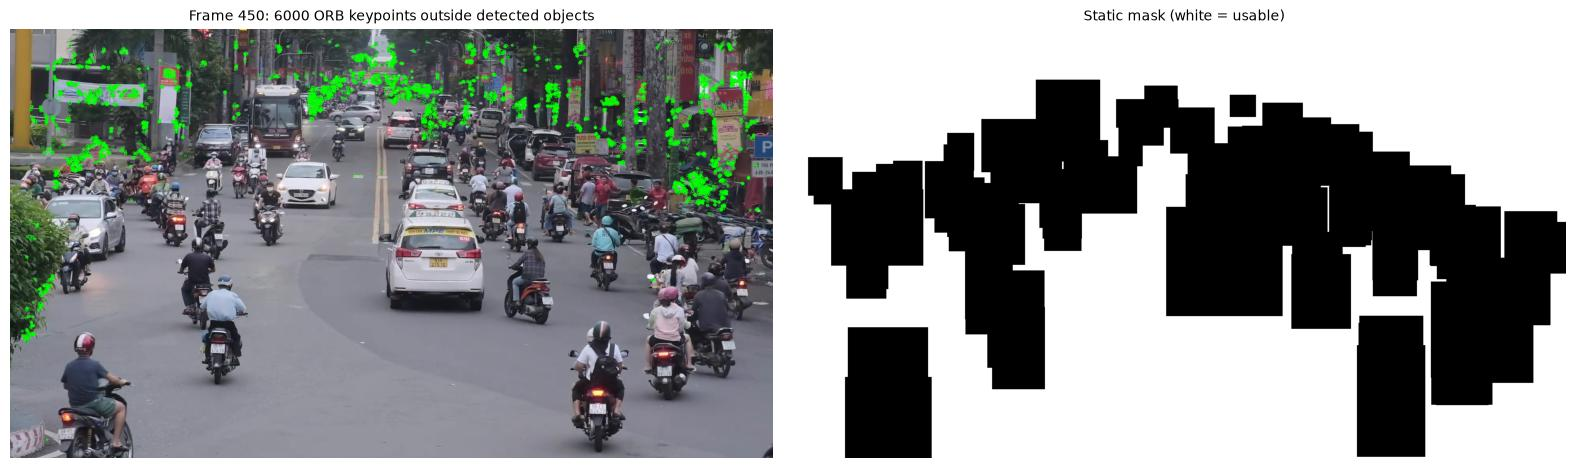

Share of reference keypoints in the lower half of the image (y > 540): 2.9%


In [3]:
REFERENCE_FRAME = 450  # middle of the clip, so the largest displacement to any frame is small
MASK_MARGIN = 12       # px added around each box


def static_mask(frame_index: int) -> np.ndarray:
    mask = np.full((H, W), 255, np.uint8)
    for d in detection_records[frame_index]["detections"]:
        if d["class_name"] == "traffic light":
            continue
        x1, y1, x2, y2 = (int(v) for v in d["bbox_xyxy"])
        mask[max(0, y1 - MASK_MARGIN):y2 + MASK_MARGIN, max(0, x1 - MASK_MARGIN):x2 + MASK_MARGIN] = 0
    return mask


reference_image = read_frame_at(SAMPLE_VIDEO, REFERENCE_FRAME)["image"]
reference_gray = cv2.cvtColor(reference_image, cv2.COLOR_BGR2GRAY)
orb = cv2.ORB_create(6000)
matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
reference_kp, reference_des = orb.detectAndCompute(reference_gray, static_mask(REFERENCE_FRAME))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
preview = cv2.drawKeypoints(reference_image, reference_kp, None, color=(0, 255, 0))
axes[0].imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Frame {REFERENCE_FRAME}: {len(reference_kp)} ORB keypoints outside detected objects", fontsize=10)
axes[1].imshow(static_mask(REFERENCE_FRAME), cmap="gray")
axes[1].set_title("Static mask (white = usable)", fontsize=10)
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

keypoint_y = np.array([k.pt[1] for k in reference_kp])
print(f"Share of reference keypoints in the lower half of the image (y > 540): {(keypoint_y > 540).mean():.1%}")

### 2.2 Estimating the transform for every frame

For each frame we match its keypoints directly to the reference frame, using Lowe's ratio test to drop ambiguous matches. Matching directly avoids the drift that accumulates when chaining frame-to-frame estimates. We then fit two candidate models with RANSAC:

- **Similarity** (4 degrees of freedom: shift, rotation, uniform scale).
- **Homography** (8 degrees of freedom). This is the geometrically correct model for a camera rotating around a fixed point.

The homography is fitted on every 15th frame only, for comparison.

In [4]:
SAMPLE_STEP = 15
similarity_params = np.zeros((N_FRAMES, 4))  # a, b, tx, ty: x' = a*x - b*y + tx, y' = b*x + a*y + ty
inlier_counts = np.zeros(N_FRAMES, dtype=int)
match_counts = np.zeros(N_FRAMES, dtype=int)
homographies, sample_images = {}, {}
lower_half_share = []

start = time.perf_counter()
for record in iter_frames(SAMPLE_VIDEO):
    k = record["frame_index"]
    gray = cv2.cvtColor(record["image"], cv2.COLOR_BGR2GRAY)
    kp, des = orb.detectAndCompute(gray, static_mask(k))
    pairs = [p[0] for p in matcher.knnMatch(des, reference_des, k=2) if len(p) == 2 and p[0].distance < 0.75 * p[1].distance]
    src = np.float32([kp[m.queryIdx].pt for m in pairs])
    dst = np.float32([reference_kp[m.trainIdx].pt for m in pairs])
    S, inliers = cv2.estimateAffinePartial2D(src, dst, method=cv2.RANSAC, ransacReprojThreshold=2.0, maxIters=5000)
    similarity_params[k] = [S[0, 0], S[1, 0], S[0, 2], S[1, 2]]
    inlier_counts[k], match_counts[k] = int(inliers.sum()), len(pairs)
    if k % SAMPLE_STEP == 0 or k == N_FRAMES - 1:
        sample_images[k] = record["image"]
        homographies[k], h_inliers = cv2.findHomography(src, dst, cv2.RANSAC, 2.0, maxIters=5000)
        lower_half_share.append(float((dst[h_inliers.ravel() == 1][:, 1] > 540).mean()))
elapsed = time.perf_counter() - start

print(f"Registered {N_FRAMES} frames in {elapsed:.0f} s ({elapsed / N_FRAMES * 1000:.0f} ms per frame)")
print(f"Matches: median {np.median(match_counts):.0f} | similarity inliers: median {np.median(inlier_counts):.0f}, "
      f"minimum {inlier_counts.min()}, median ratio {np.median(inlier_counts / match_counts):.1%}")
print(f"Share of inlier matches in the lower half (y > 540), median: {np.median(lower_half_share):.1%}")

Registered 900 frames in 68 s (76 ms per frame)
Matches: median 1886 | similarity inliers: median 1564, minimum 906, median ratio 84.1%
Share of inlier matches in the lower half (y > 540), median: 1.2%


Masking and direct matching raise the inlier ratio far above the 10–16% of Notebook 00. But note the last line: almost no matches lie in the lower half of the image, because bare asphalt has little texture. A flexible model is then **extrapolating** over the road surface, which is exactly where we want to draw geometry.

### 2.3 Which model? Measuring residuals on static points

To compare the models independently of the keypoints they were fitted on, we take small templates of static structures from the reference frame and search for them in each aligned frame with **template matching**. A perfect alignment finds each template at displacement 0. Matches with normalized correlation below 0.8 are skipped, since the point is then likely occluded by traffic. Template matching works in whole pixels, so residuals are integers or small combinations of them.

In [5]:
STATIC_POINTS = {  # (x, y) in the reference frame: visible in it, not on a moving object
    "banner": (222, 160),
    "shop_sign": (1450, 288),
    "yellow_pole": (30, 285),
    "p_sign": (1893, 300),
    "barrier_bottom_left": (42, 1000),
    "road_patch_corner": (752, 577),
}
TEMPLATE_HALF, SEARCH_RADIUS, MIN_NCC = 25, 170, 0.8


def template_displacement(gray: np.ndarray, x: int, y: int) -> tuple[float, float]:
    template = reference_gray[y - TEMPLATE_HALF:y + TEMPLATE_HALF, x - TEMPLATE_HALF:x + TEMPLATE_HALF]
    y0, x0 = max(0, y - SEARCH_RADIUS), max(0, x - SEARCH_RADIUS)
    window = gray[y0:min(H, y + SEARCH_RADIUS), x0:min(W, x + SEARCH_RADIUS)]
    result = cv2.matchTemplate(window, template, cv2.TM_CCOEFF_NORMED)
    _, score, _, location = cv2.minMaxLoc(result)
    return float(np.hypot(location[0] + x0 + TEMPLATE_HALF - x, location[1] + y0 + TEMPLATE_HALF - y)), float(score)


residuals = {name: {"raw": [], "homography": [], "similarity": []} for name in STATIC_POINTS}
for k, image in sample_images.items():
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    aligned = {
        "raw": gray,
        "homography": cv2.warpPerspective(gray, homographies[k], (W, H)),
        "similarity": cv2.warpAffine(gray, similarity_matrix(similarity_params[k]), (W, H)),
    }
    for name, (x, y) in STATIC_POINTS.items():
        for method, candidate in aligned.items():
            distance, score = template_displacement(candidate, x, y)
            if score >= MIN_NCC:
                residuals[name][method].append(distance)

print(f"{'static point':<22}{'raw med':>9}{'raw max':>9}{'H med':>8}{'H max':>8}{'S med':>8}{'S max':>8}   n(H/S)")
for name, r in residuals.items():
    print(f"{name:<22}{np.median(r['raw']):>9.1f}{np.max(r['raw']):>9.1f}"
          f"{np.median(r['homography']):>8.2f}{np.max(r['homography']):>8.2f}"
          f"{np.median(r['similarity']):>8.2f}{np.max(r['similarity']):>8.2f}   {len(r['homography'])}/{len(r['similarity'])}")

static point            raw med  raw max   H med   H max   S med   S max   n(H/S)
banner                     25.7     87.3    1.00    5.00    1.00    3.16   61/61
shop_sign                  27.2     97.9    0.00    1.00    0.00    1.00   61/61
yellow_pole                32.8     87.1    1.00    3.00    1.00    3.00   50/51
p_sign                     23.2     46.0    0.00    1.00    0.00    1.00   35/35
barrier_bottom_left        25.8     61.3    2.00   17.46    1.00    2.24   45/45
road_patch_corner          26.2     88.8    1.00   92.40    0.00    2.24   30/29


**Decision: the similarity transform.** The homography is the correct model in theory, but nearly all its support lies in the upper half of the image. Its errors show up on the points lowest in the image, on the road surface and at the bottom-left barrier. The similarity has fewer degrees of freedom to extrapolate with, and its residuals there are small. The scale stays very close to 1, so nothing in this clip calls for more flexibility.

### 2.4 The camera motion over time

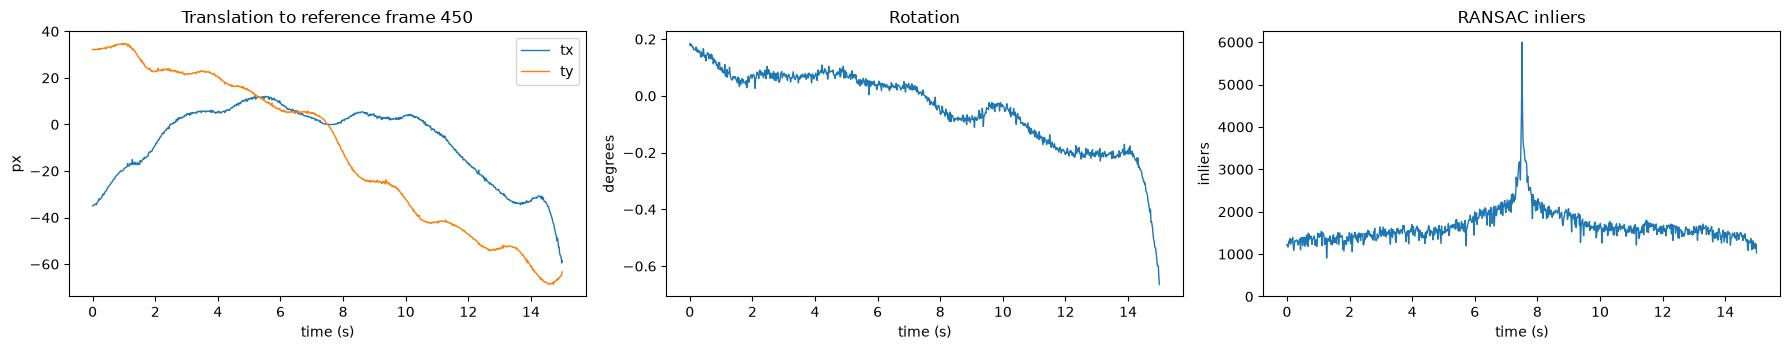

scale 0.9982 - 1.0013 | rotation -0.66 - 0.18 deg
tx -59.5 - 12.1 px | ty -68.8 - 34.8 px
frame-to-frame change of (tx, ty): median 0.42 px, 99th percentile 1.59 px


In [6]:
rotation_deg = np.degrees(np.arctan2(similarity_params[:, 1], similarity_params[:, 0]))
times_s = np.arange(N_FRAMES) / FPS

fig, axes = plt.subplots(1, 3, figsize=(18, 3.6))
axes[0].plot(times_s, similarity_params[:, 2], label="tx", linewidth=1)
axes[0].plot(times_s, similarity_params[:, 3], label="ty", linewidth=1)
axes[0].set(xlabel="time (s)", ylabel="px", title=f"Translation to reference frame {REFERENCE_FRAME}")
axes[0].legend()
axes[1].plot(times_s, rotation_deg, linewidth=1)
axes[1].set(xlabel="time (s)", ylabel="degrees", title="Rotation")
axes[2].plot(times_s, inlier_counts, linewidth=1)
axes[2].set(xlabel="time (s)", ylabel="inliers", title="RANSAC inliers", ylim=(0, None))
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "camera_motion.png", dpi=100)
plt.show()

frame_step = np.hypot(*np.diff(similarity_params[:, 2:], axis=0).T)
print(f"scale {similarity_params[:, 0].min():.4f} - {similarity_params[:, 0].max():.4f} | rotation {rotation_deg.min():.2f} - {rotation_deg.max():.2f} deg")
print(f"tx {similarity_params[:, 2].min():.1f} - {similarity_params[:, 2].max():.1f} px | ty {similarity_params[:, 3].min():.1f} - {similarity_params[:, 3].max():.1f} px")
print(f"frame-to-frame change of (tx, ty): median {np.median(frame_step):.2f} px, 99th percentile {np.percentile(frame_step, 99):.2f} px")

### 2.5 The stabilized background

The per-pixel median of aligned frames removes moving traffic. Compare it with the median of the *unaligned* frames: it reveals the road markings that Notebook 00 could not see.

Vehicles that stand still for most of the clip, such as the bus, remain in the median. So do ghost smears of slowly moving queues. Both are information, not errors.

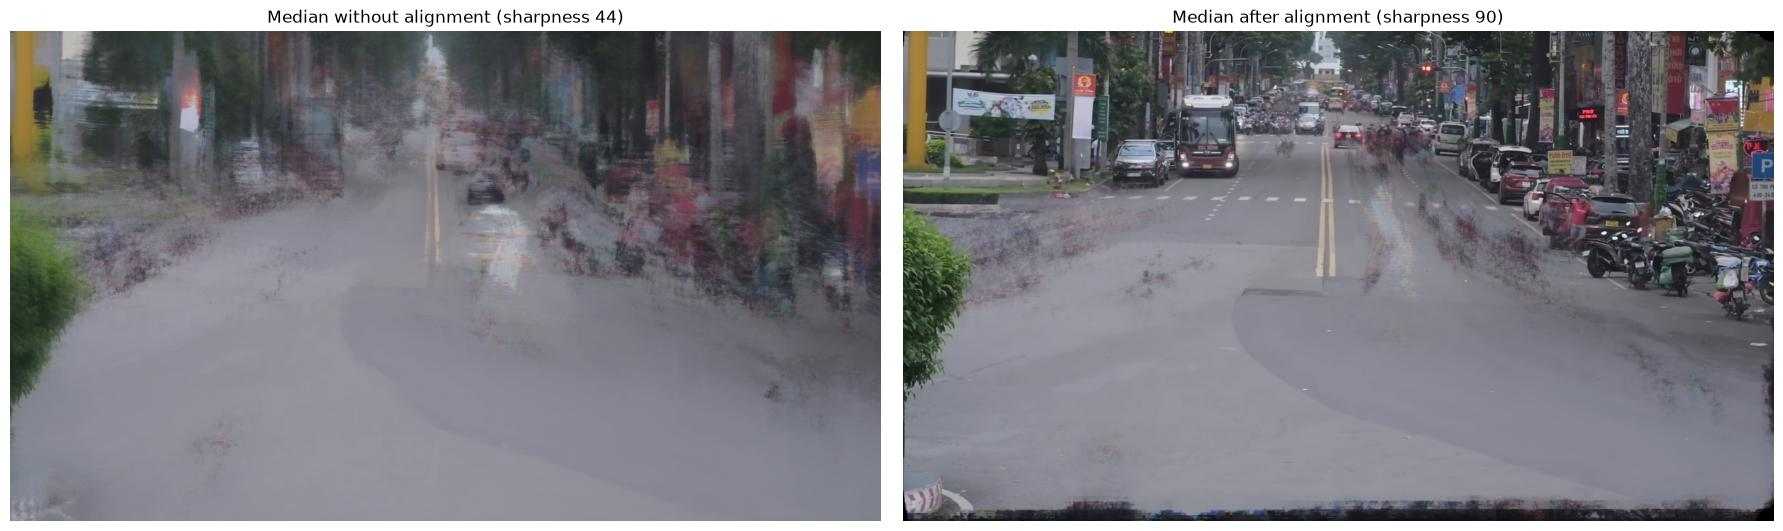

In [7]:
aligned_samples = [cv2.warpAffine(image, similarity_matrix(similarity_params[k]), (W, H)) for k, image in sorted(sample_images.items())]
stabilized = np.median(np.stack(aligned_samples), axis=0).astype(np.uint8)
unaligned = np.median(np.stack([image for _, image in sorted(sample_images.items())]), axis=0).astype(np.uint8)
assert cv2.imwrite(str(OUTPUT_DIR / "stabilized_background.png"), stabilized)
stabilized_rgb = cv2.cvtColor(stabilized, cv2.COLOR_BGR2RGB)


def sharpness(image: np.ndarray) -> float:
    return float(cv2.Laplacian(cv2.cvtColor(image, cv2.COLOR_BGR2GRAY), cv2.CV_64F).var())


sharpness_raw, sharpness_stabilized = sharpness(unaligned), sharpness(stabilized)
fig, axes = plt.subplots(1, 2, figsize=(18, 5.2))
axes[0].imshow(cv2.cvtColor(unaligned, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Median without alignment (sharpness {sharpness_raw:.0f})")
axes[1].imshow(stabilized_rgb)
axes[1].set_title(f"Median after alignment (sharpness {sharpness_stabilized:.0f})")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "background_before_after.jpg", dpi=90)
plt.show()

### 2.6 Which part of the reference frame is always visible?

The camera moves, so some reference coordinates fall outside the image in some frames. Geometry used by rules should lie in the region visible in **every** frame; otherwise a rule silently stops working when the camera moves.

In [8]:
corners = np.array([[0, 0], [W, 0], [W, H], [0, H]], dtype=np.float64)
lefts, rights, tops, bottoms = [], [], [], []
for params in similarity_params:
    mapped = cv2.transform(corners[None], similarity_matrix(params))[0]
    lefts.append(max(mapped[0, 0], mapped[3, 0])); rights.append(min(mapped[1, 0], mapped[2, 0]))
    tops.append(max(mapped[0, 1], mapped[1, 1])); bottoms.append(min(mapped[2, 1], mapped[3, 1]))
ALWAYS_VISIBLE = [float(np.ceil(max(lefts))), float(np.ceil(max(tops))), float(np.floor(min(rights))), float(np.floor(min(bottoms)))]
print("Always visible (x1, y1, x2, y2) in reference coordinates:", ALWAYS_VISIBLE)

Always visible (x1, y1, x2, y2) in reference coordinates: [13.0, 39.0, 1860.0, 993.0]


Next, we express every trajectory in reference coordinates.

In [9]:
def to_reference(frame_index: int, points) -> np.ndarray:
    return frame_to_reference(similarity_params[frame_index], points)


def from_reference(frame_index: int, points) -> np.ndarray:
    return reference_to_frame(similarity_params[frame_index], points)


reference_tracks = {
    track_id: np.vstack([to_reference(f, [p]) for f, p in zip(t["frames"], t["points"])]) for track_id, t in tracks.items()
}

## 3. Inspecting the scene

With a stable background, the scene can be read properly. Axes below show **reference coordinates**, so coordinates can be read directly from the figures.

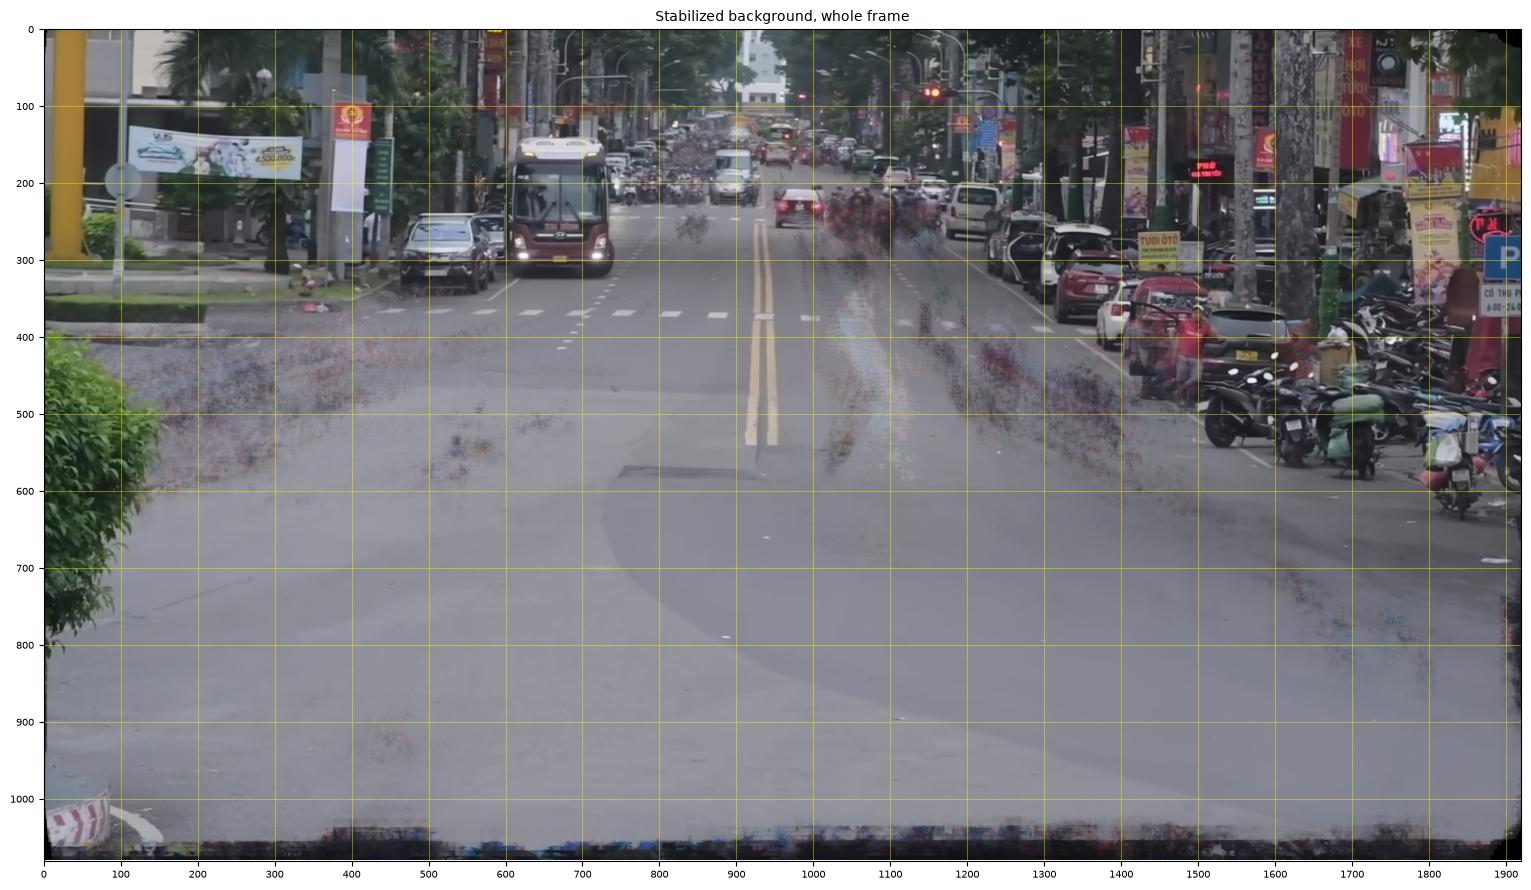

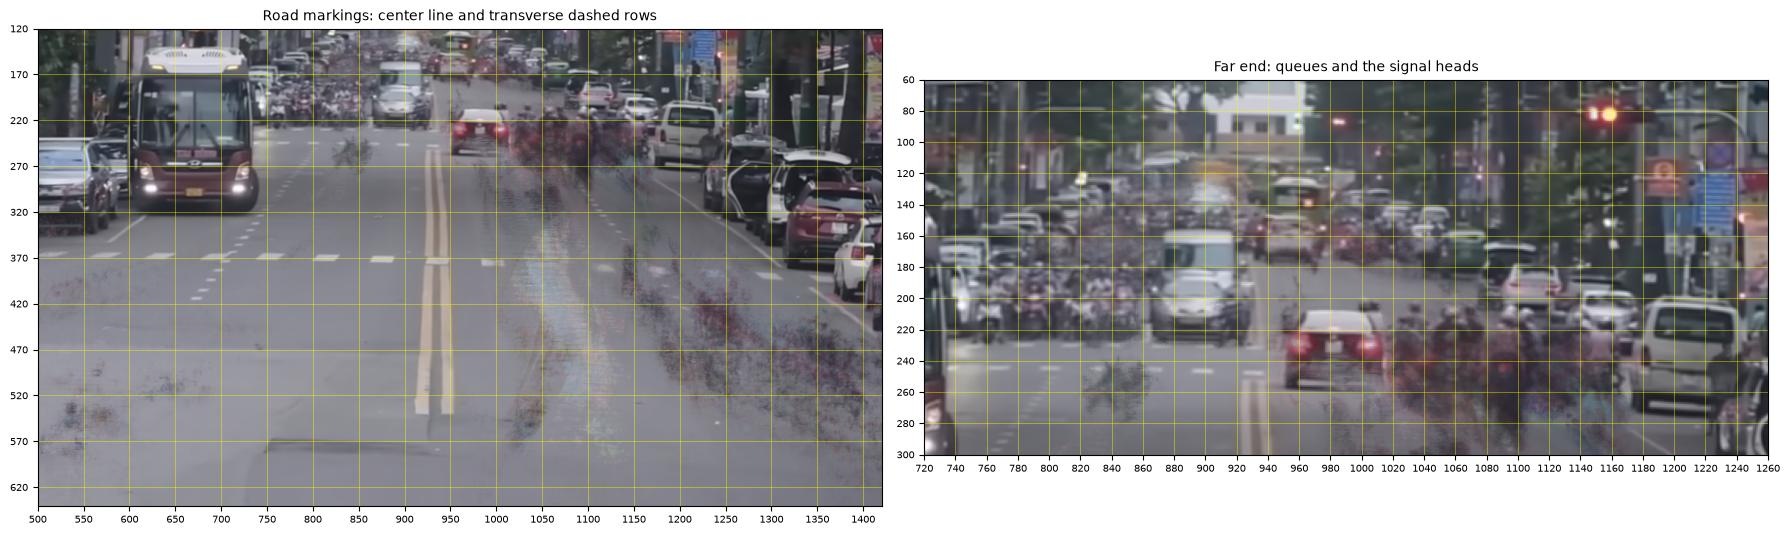

In [10]:
def show_with_grid(ax, x_range, y_range, step, title):
    ax.imshow(stabilized_rgb)
    ax.set_xlim(*x_range); ax.set_ylim(y_range[1], y_range[0])
    ax.set_xticks(np.arange(x_range[0], x_range[1] + 1, step)); ax.set_yticks(np.arange(y_range[0], y_range[1] + 1, step))
    ax.grid(color="yellow", linewidth=0.4, alpha=0.7)
    ax.tick_params(labelsize=7)
    ax.set_title(title, fontsize=10)


fig, ax = plt.subplots(figsize=(16, 9))
show_with_grid(ax, (0, W), (0, H), 100, "Stabilized background, whole frame")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "scene_grid_full.jpg", dpi=90)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
show_with_grid(axes[0], (500, 1420), (120, 640), 50, "Road markings: center line and transverse dashed rows")
show_with_grid(axes[1], (720, 1260), (60, 300), 20, "Far end: queues and the signal heads")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "scene_grid_zoom.jpg", dpi=90)
plt.show()

**What the markings show** (visual reading of the figures above):

- A **double yellow center line** runs nearly vertically in the image, from about y = 250 to y = 540, at x ≈ 930. It separates two carriageways.
- Two **transverse dashed rows** cross the road, at about y ≈ 247 (*far row*) and y ≈ 367–392 (*near row*). They are not solid stop lines, and **their legal meaning cannot be determined from the video**.
- Solid white **edge lines** run on both sides, separating the traffic lanes from parked vehicles.
- Below the near row, the road opens into a **wide marking-free area** with a curved pavement seam: most likely a junction.
- A **bus** with headlights on faces the camera behind the near row. It stays sharp in the median, so it stands still for most of the clip, and vehicles wait behind the far row on the left for much of it. Traffic on the left carriageway therefore faces the camera, and whatever holds it is not visible to the camera.
- **Signal heads** are mounted beyond the far row, facing the camera. They therefore face traffic travelling *away* from the camera.

### How do vehicles actually move?

Each trajectory is colored by its net displacement: mostly upward, mostly downward, mostly leftward, mostly rightward, or static.

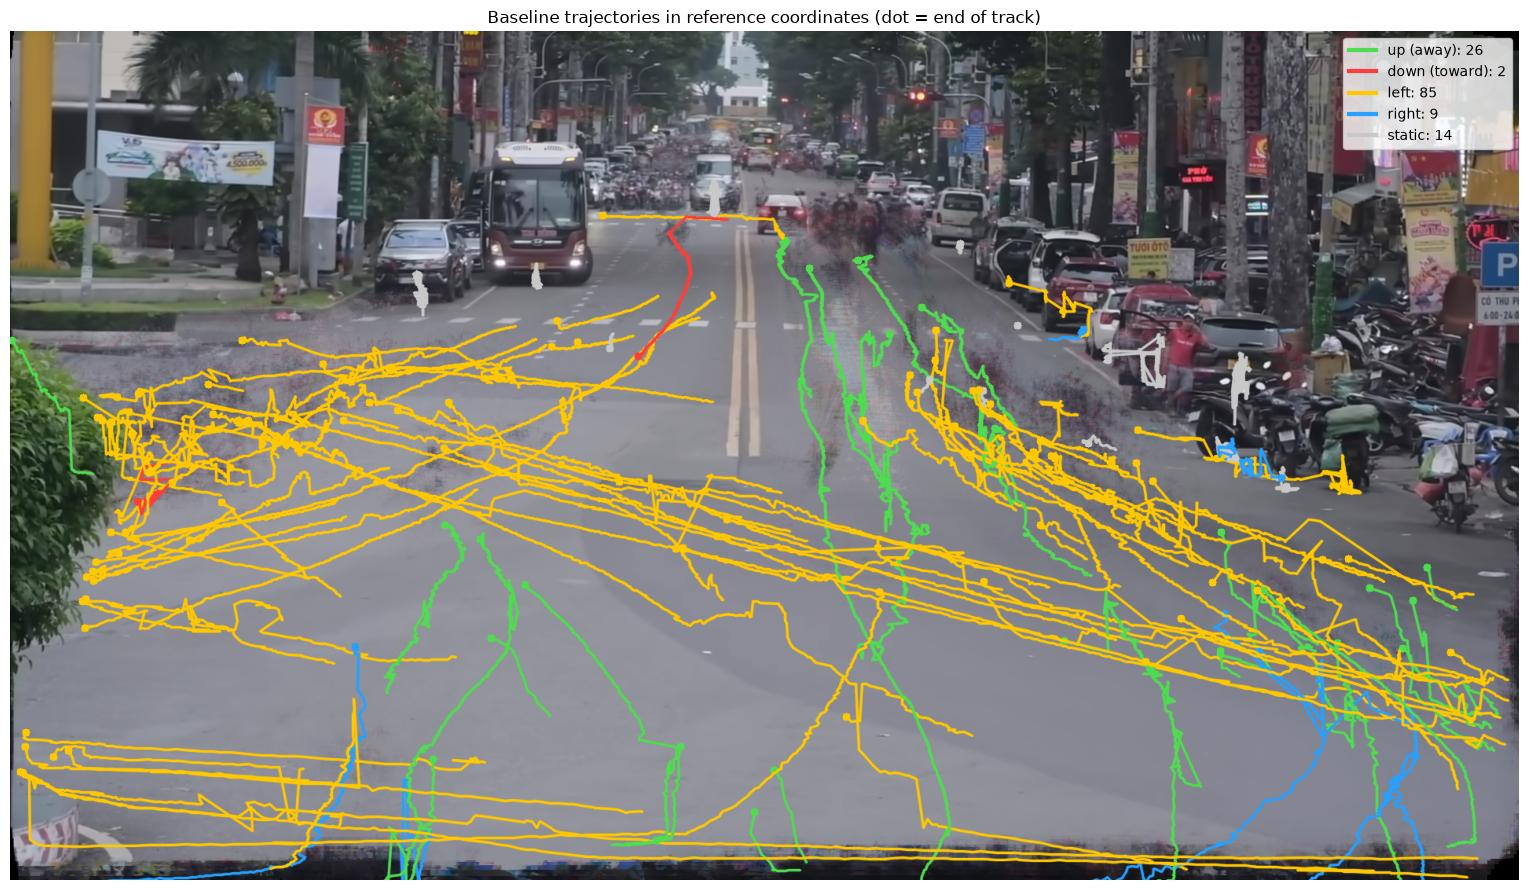

Net direction of tracks: {'up (away)': 26, 'down (toward)': 2, 'left': 85, 'right': 9, 'static': 14}


In [11]:
DIRECTION_COLORS_RGB = {"up (away)": (80, 220, 80), "down (toward)": (255, 60, 60), "left": (255, 200, 0), "right": (40, 160, 255), "static": (200, 200, 200)}
STATIC_NET_DISPLACEMENT = 40  # px


def net_direction(points: np.ndarray) -> str:
    dx, dy = points[-1] - points[0]
    if np.hypot(dx, dy) < STATIC_NET_DISPLACEMENT:
        return "static"
    if abs(dx) > abs(dy):
        return "right" if dx > 0 else "left"
    return "up (away)" if dy < 0 else "down (toward)"


canvas = stabilized_rgb.copy()
direction_counts = {name: 0 for name in DIRECTION_COLORS_RGB}
for points in reference_tracks.values():
    name = net_direction(points)
    direction_counts[name] += 1
    cv2.polylines(canvas, [points.astype(np.int32)], False, DIRECTION_COLORS_RGB[name], 2, cv2.LINE_AA)
    cv2.circle(canvas, tuple(points[-1].astype(int).tolist()), 5, DIRECTION_COLORS_RGB[name], -1)

fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(canvas)
handles = [Line2D([0], [0], color=np.array(c) / 255, linewidth=3, label=f"{n}: {direction_counts[n]}") for n, c in DIRECTION_COLORS_RGB.items()]
ax.legend(handles=handles, loc="upper right", fontsize=10)
ax.set_title("Baseline trajectories in reference coordinates (dot = end of track)")
ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "trajectories_reference.jpg", dpi=90)
plt.show()
print("Net direction of tracks:", direction_counts)

**Reading the flows.** This refines the description in Notebook 00, which could only see sampled frames:

- The dominant flow crosses the marking-free area **diagonally from the lower right toward the left**. That is consistent with a junction, with a flow turning or crossing through it.
- Part of that flow bends up and continues **away from the camera on the right carriageway**, to the right of the center line.
- Few vehicles tracked on the left carriageway move more than a few pixels between samples, consistent with the mostly stationary bus and waiting vehicles.

No fixed direction applies inside the junction, so direction rules should only cover the two carriageways above it.

## 4. Scene geometry

All coordinates are **reference coordinates**, read from the grids above. The geometry is deliberately coarse: a rule needs to decide which region a vehicle is in, not trace lane paint to the pixel.

**Allowed direction.** Lanes converge at a vanishing point, so the direction at a position is defined relative to it:

- `away_from_camera` — motion toward the vanishing point;
- `toward_camera` — motion away from it.

We compute the vanishing point from the three road lines rather than guessing it.

In [12]:
CENTER_LINE = [[930, 250], [933, 540]]
LEFT_EDGE = [[733, 247], [556, 365]]
RIGHT_EDGE = [[1125, 250], [1535, 540]]


def line_coefficients(line):
    # Homogeneous line through two points.
    (x1, y1), (x2, y2) = line
    return np.cross([x1, y1, 1.0], [x2, y2, 1.0])


coefficients = np.array([line_coefficients(line) for line in (CENTER_LINE, LEFT_EDGE, RIGHT_EDGE)])
coefficients /= np.linalg.norm(coefficients[:, :2], axis=1, keepdims=True)
_, _, vh = np.linalg.svd(coefficients)
vanishing_point = vh[-1, :2] / vh[-1, 2]
line_distances = np.abs(coefficients @ np.array([*vanishing_point, 1.0]))
print(f"Vanishing point from three lines: ({vanishing_point[0]:.1f}, {vanishing_point[1]:.1f}); "
      f"distance to each line: {np.round(line_distances, 1).tolist()} px")

Vanishing point from three lines: (930.2, 113.9); distance to each line: [1.6, 1.4, 1.4] px


In [13]:
SCENE = {
    "schema_version": 1,
    "scene_id": "video-test",
    "video": {"file": "data/video-test.mp4", "width": W, "height": H},
    "coordinates": {
        "system": "reference_frame_pixels",
        "reference_frame_index": REFERENCE_FRAME,
        "origin": "top-left, y down",
        "frame_transforms": "outputs/04_traffic_scene_configuration/video-test.camera_motion.json",
        "always_visible_xyxy": ALWAYS_VISIBLE,
    },
    "vanishing_point": [round(float(v), 1) for v in vanishing_point],
    "regions": [
        {"id": "left_carriageway", "kind": "carriageway", "polygon": [[733, 247], [930, 250], [931, 380], [556, 369]],
         "allowed_direction": "toward_camera", "direction_tolerance_deg": 60,
         "description": "Lanes left of the center line, between the far and near dashed rows"},
        {"id": "right_carriageway", "kind": "carriageway", "polygon": [[934, 250], [1125, 254], [1535, 540], [937, 540]],
         "allowed_direction": "away_from_camera", "direction_tolerance_deg": 60,
         "description": "Lanes right of the center line, from the far row down to the end of the center line"},
        {"id": "junction", "kind": "junction",
         "polygon": [[440, 365], [931, 380], [937, 540], [1535, 540], [1855, 700], [1855, 990], [15, 990], [15, 800], [100, 720], [100, 520], [60, 405], [300, 400]],
         "allowed_direction": None, "direction_tolerance_deg": None,
         "description": "Wide marking-free area; flows turn and cross here, so no direction applies"},
        {"id": "parking_left", "kind": "excluded", "polygon": [[733, 244], [556, 369], [440, 365], [440, 244]],
         "allowed_direction": None, "direction_tolerance_deg": None,
         "description": "Parked cars left of the left edge line"},
        {"id": "parking_right", "kind": "excluded", "polygon": [[1125, 254], [1535, 540], [1855, 700], [1855, 254]],
         "allowed_direction": None, "direction_tolerance_deg": None,
         "description": "Parked vehicles and sidewalk right of the right edge line"},
        {"id": "far_zone", "kind": "far_zone", "polygon": [[740, 160], [1125, 160], [1125, 254], [740, 244]],
         "allowed_direction": None, "direction_tolerance_deg": None,
         "description": "Road beyond the far row; vehicles are small and the tracker often loses them, so no rule is applied"},
    ],
    "lines": [
        {"id": "center_line", "kind": "double_yellow", "points": CENTER_LINE,
         "description": "Double yellow center line separating the carriageways"},
        {"id": "far_row", "kind": "transverse_dashed", "points": [[740, 244], [1125, 254]],
         "description": "Dashed row across the road; visible at x <= 940, extrapolated across the right carriageway, where queues hide it"},
        {"id": "near_row", "kind": "transverse_dashed", "points": [[440, 365], [1310, 392]],
         "description": "Dashed row at the entrance of the junction"},
        {"id": "left_edge", "kind": "edge_line", "points": LEFT_EDGE, "description": "Solid edge line extended upward"},
        {"id": "right_edge", "kind": "edge_line", "points": RIGHT_EDGE, "description": "Solid edge line separating lanes from parking"},
    ],
    "signals": [
        {"id": "signal_main", "roi_xyxy": [1138, 68, 1195, 96], "faces": "camera",
         "governs_regions": ["right_carriageway"], "governs_status": "unverified",
         "description": "Signal heads mounted beyond the far row, facing the camera"},
    ],
    "assumptions": [
        "Geometry is in pixels of the reference frame; the camera is not calibrated, so it gives no metric distances or speeds.",
        "Scene geometry is valid only for this clip and this camera position.",
        "The legal meaning of the transverse dashed rows is unknown; neither is asserted to be a stop line.",
        "signal_main faces traffic moving away from the camera, so it is assumed to govern the right carriageway. Notebook 04 could not confirm this from the data: the status is 'unverified'.",
        "No signal facing the left carriageway is visible, so its signal state is unobservable in this video.",
    ],
}
print(f"{len(SCENE['regions'])} regions, {len(SCENE['lines'])} lines, {len(SCENE['signals'])} signal(s)")

6 regions, 5 lines, 1 signal(s)


### Visualizing the configuration

The drawing function can project the geometry into any frame's pixels, which section 7 uses to check it against the video.

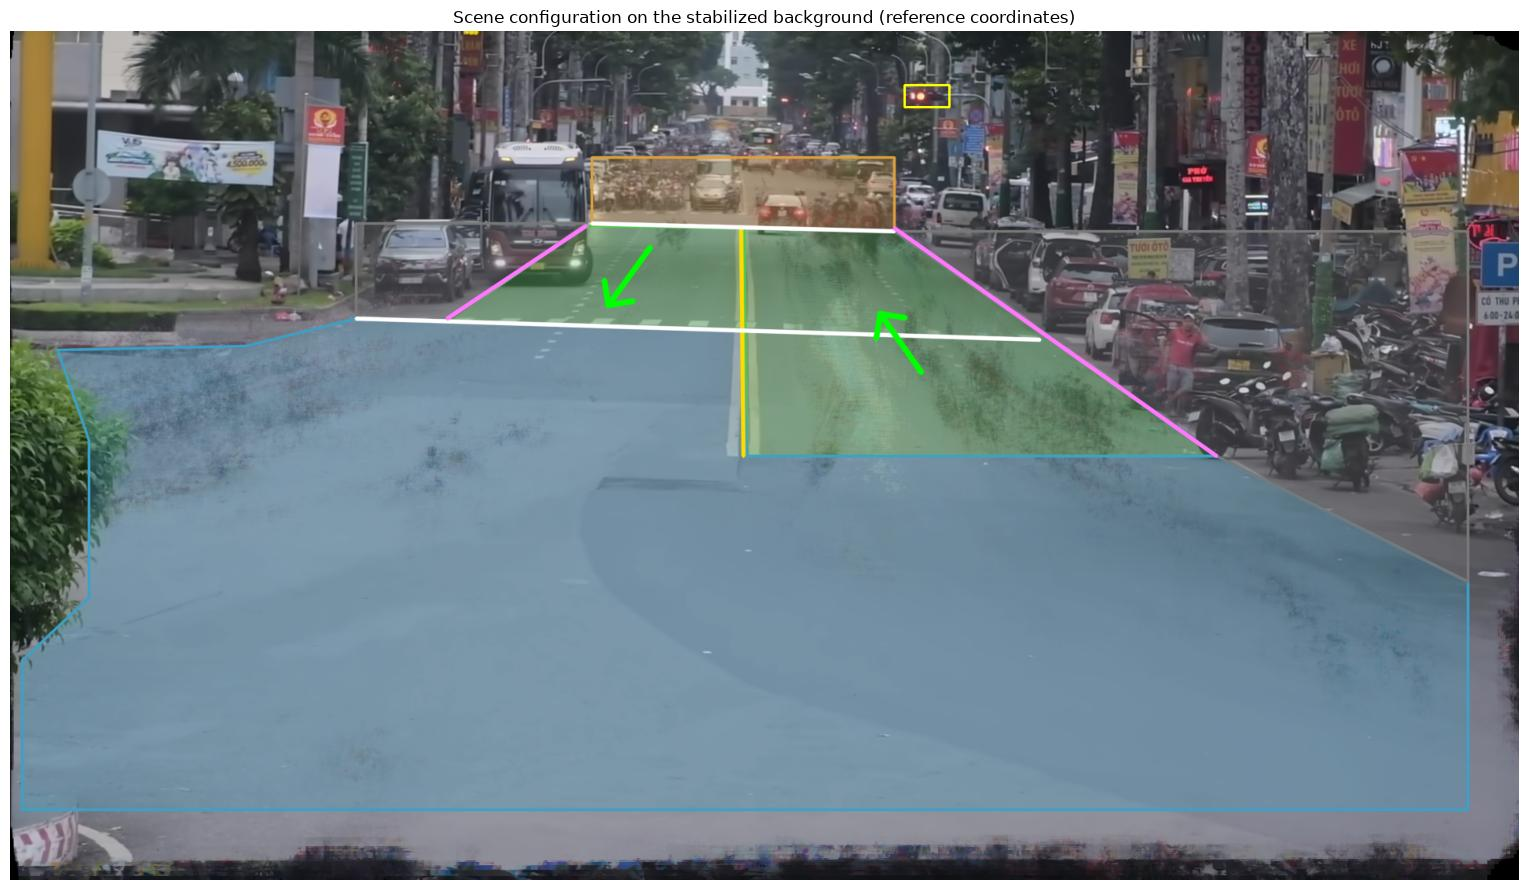

In [14]:
REGION_COLORS_BGR = {"carriageway": (80, 200, 80), "junction": (200, 160, 60), "excluded": (120, 120, 120), "far_zone": (60, 160, 220)}
LINE_COLORS_BGR = {"double_yellow": (0, 220, 255), "transverse_dashed": (255, 255, 255), "edge_line": (255, 120, 255)}


def draw_scene(image: np.ndarray, scene: dict, mapper=None, alpha: float = 0.28) -> np.ndarray:
    # Draw the scene on a BGR image; mapper converts reference coordinates into the image's pixels (default: identity).
    mapper = mapper or (lambda points: np.asarray(points, dtype=np.float64))
    to_pixels = lambda points: np.round(mapper(points)).astype(np.int32)
    overlay = image.copy()
    for region in scene["regions"]:
        cv2.fillPoly(overlay, [to_pixels(region["polygon"])], REGION_COLORS_BGR[region["kind"]])
    canvas = cv2.addWeighted(overlay, alpha, image, 1 - alpha, 0)
    for region in scene["regions"]:
        cv2.polylines(canvas, [to_pixels(region["polygon"])], True, REGION_COLORS_BGR[region["kind"]], 2, cv2.LINE_AA)
    for line in scene["lines"]:
        cv2.polylines(canvas, [to_pixels(line["points"])], False, LINE_COLORS_BGR[line["kind"]], 3, cv2.LINE_AA)
    vp = np.array(scene["vanishing_point"], dtype=np.float64)
    for region in scene["regions"]:
        if region["allowed_direction"] is None:
            continue
        center = np.array(region["polygon"], dtype=np.float64).mean(axis=0)
        unit = (vp - center) / np.linalg.norm(vp - center)
        sign = 1 if region["allowed_direction"] == "away_from_camera" else -1
        (start, end) = to_pixels([center - sign * 45 * unit, center + sign * 45 * unit])
        cv2.arrowedLine(canvas, tuple(start.tolist()), tuple(end.tolist()), (0, 255, 0), 6, cv2.LINE_AA, tipLength=0.35)
    for signal in scene["signals"]:
        x1, y1, x2, y2 = signal["roi_xyxy"]
        (a, b) = to_pixels([[x1, y1], [x2, y2]])
        cv2.rectangle(canvas, tuple(a.tolist()), tuple(b.tolist()), (0, 255, 255), 2)
    return canvas


fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(cv2.cvtColor(draw_scene(stabilized, SCENE), cv2.COLOR_BGR2RGB))
ax.set_title("Scene configuration on the stabilized background (reference coordinates)")
ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "scene_configuration.jpg", dpi=90)
plt.show()

## 5. The traffic signal

### 5.1 Reading the signal state

The detector locates signal heads but gives no state (Notebook 02). We read the state from color inside the ROI, counting bright pixels whose hue falls in the red or green range. The state is:

- `red` or `green` when one color has enough bright pixels and clearly dominates;
- `unknown` otherwise. **Missing evidence stays `unknown`; it is never treated as red.**

Because the ROI is in reference coordinates, it stays on the lamps despite camera motion, which also tests the registration.

In [15]:
MIN_LAMP_PIXELS, DOMINANCE = 8, 2.0
signal_config = SCENE["signals"][0]


def read_signal_state(aligned_bgr: np.ndarray, roi_xyxy) -> dict:
    x1, y1, x2, y2 = roi_xyxy
    hsv = cv2.cvtColor(aligned_bgr[y1:y2, x1:x2], cv2.COLOR_BGR2HSV)
    hue, saturation, value = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    bright = value >= 170
    red = int((bright & ((hue <= 12) | (hue >= 165)) & (saturation >= 90)).sum())
    green = int((bright & (hue >= 40) & (hue <= 95) & (saturation >= 60)).sum())
    if red >= MIN_LAMP_PIXELS and red > DOMINANCE * green:
        state = "red"
    elif green >= MIN_LAMP_PIXELS and green > DOMINANCE * red:
        state = "green"
    else:
        state = "unknown"
    return {"state": state, "red_pixels": red, "green_pixels": green}


# Queue areas for section 5.2: on the governed carriageway, and a control on the other side.
ACTIVITY_REGIONS = {"right queue (x 1000-1130, y 215-300)": (1000, 215, 1130, 300), "left queue (x 740-920, y 195-240)": (740, 195, 920, 240)}
ACTIVITY_LAG = 15  # frames between the two images compared

signal_records, activity = [], {name: [] for name in ACTIVITY_REGIONS}
history = []
for record in iter_frames(SAMPLE_VIDEO):
    k = record["frame_index"]
    aligned = cv2.warpAffine(record["image"], similarity_matrix(similarity_params[k]), (W, H))
    signal_records.append({"frame_index": k, "timestamp_s": record["timestamp_s"], **read_signal_state(aligned, signal_config["roi_xyxy"])})
    gray = cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY).astype(np.int16)
    history.append(gray[150:320, 720:1160])  # only the area needed, to keep memory low
    if len(history) > ACTIVITY_LAG:
        previous = history.pop(0)
        for name, (x1, y1, x2, y2) in ACTIVITY_REGIONS.items():
            current_patch, previous_patch = history[-1][y1 - 150:y2 - 150, x1 - 720:x2 - 720], previous[y1 - 150:y2 - 150, x1 - 720:x2 - 720]
            activity[name].append(float(np.abs(current_patch - previous_patch).mean()))
    else:
        for name in ACTIVITY_REGIONS:
            activity[name].append(np.nan)

states = np.array([r["state"] for r in signal_records])
counts = {s: int((states == s).sum()) for s in ("red", "green", "unknown")}
changes = np.flatnonzero(states[1:] != states[:-1]) + 1
print("Frames per state:", counts)
print("State changes at frames:", changes.tolist(), "->", [round(c / FPS, 2) for c in changes.tolist()], "s")
for c in changes:
    print(f"  frame {c}: {states[c - 1]} -> {states[c]}")

Frames per state: {'red': 553, 'green': 342, 'unknown': 5}
State changes at frames: [551, 552, 554, 558] -> [9.19, 9.21, 9.24, 9.31] s
  frame 551: red -> unknown
  frame 552: unknown -> red
  frame 554: red -> unknown
  frame 558: unknown -> green


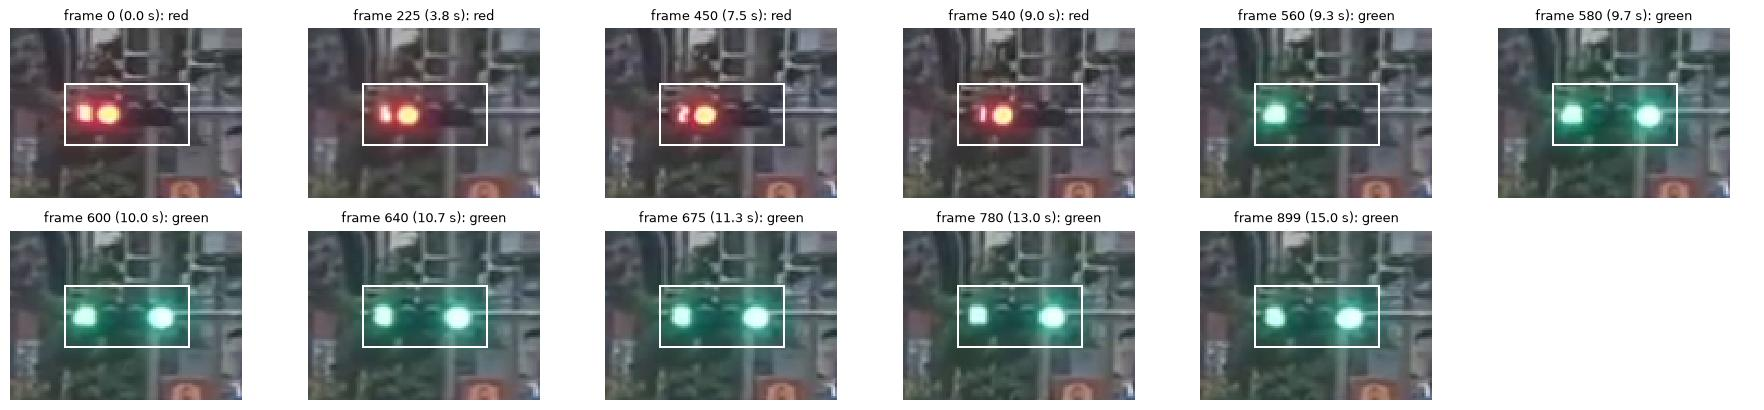

Last red frame 553 (9.23 s), first green frame 558 (9.31 s)


In [16]:
SHOW = [0, 225, 450, 540, 560, 580, 600, 640, 675, 780, 899]
x1, y1, x2, y2 = signal_config["roi_xyxy"]
margin = 25
fig, axes = plt.subplots(2, 6, figsize=(18, 4.2))
axes = axes.ravel()
for ax, k in zip(axes, SHOW):
    aligned = cv2.warpAffine(read_frame_at(SAMPLE_VIDEO, k)["image"], similarity_matrix(similarity_params[k]), (W, H))
    crop = aligned[y1 - margin:y2 + margin, x1 - margin:x2 + margin].copy()
    cv2.rectangle(crop, (margin, margin), (crop.shape[1] - margin, crop.shape[0] - margin), (255, 255, 255), 1)
    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB), interpolation="nearest")
    ax.set_title(f"frame {k} ({k / FPS:.1f} s): {signal_records[k]['state']}", fontsize=9)
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "signal_crops.jpg", dpi=100)
plt.show()

first_green = int(np.flatnonzero(states == "green")[0])
last_red = int(np.flatnonzero(states == "red")[-1])
print(f"Last red frame {last_red} ({last_red / FPS:.2f} s), first green frame {first_green} ({first_green / FPS:.2f} s)")

### 5.2 Does this signal govern the right carriageway?

So far this is an assumption, based on the head facing away-bound traffic. Data could support it: if the signal governs that traffic, vehicles should cross the far row mostly during green.

**First attempt: count tracked vehicles crossing the far row.** We count upward crossings of horizontal test lines on the right carriageway.

In [17]:
def center_line_x(y: float) -> float:
    (x1, y1), (x2, y2) = CENTER_LINE
    return x1 + (x2 - x1) * (y - y1) / (y2 - y1)


def right_edge_x(y: float) -> float:
    (x1, y1), (x2, y2) = RIGHT_EDGE
    return x1 + (x2 - x1) * (y - y1) / (y2 - y1)


red_seconds, green_seconds = counts["red"] / FPS, counts["green"] / FPS
print(f"{'test line':>10} {'crossings':>10} {'in red':>7} {'in green':>9} {'rate red (/s)':>14} {'rate green (/s)':>16}")
crossing_table = []
for test_y in (250, 290, 330, 370, 400):
    crossing_frames = []
    for track_id, points in reference_tracks.items():
        frames = tracks[track_id]["frames"]
        for i in range(1, len(points)):
            if points[i - 1, 1] > test_y >= points[i, 1] and center_line_x(test_y) < points[i, 0] < right_edge_x(test_y):
                crossing_frames.append(frames[i])
                break
    in_red = sum(states[f] == "red" for f in crossing_frames)
    in_green = sum(states[f] == "green" for f in crossing_frames)
    crossing_table.append({"y": test_y, "crossings": len(crossing_frames), "red": in_red, "green": in_green})
    print(f"{test_y:>10} {len(crossing_frames):>10} {in_red:>7} {in_green:>9} {in_red / red_seconds:>14.2f} {in_green / green_seconds:>16.2f}")

 test line  crossings  in red  in green  rate red (/s)  rate green (/s)
       250          1       1         0           0.11             0.00
       290          2       0         2           0.00             0.35
       330          3       1         2           0.11             0.35
       370          4       3         1           0.33             0.18
       400          6       4         2           0.43             0.35


Very few tracked vehicles reach the far row at all, so **these counts are too small to conclude anything**. Vehicles get small and dense there, and the tracker loses them.

**Second attempt: measure motion directly, without the detector.** We compute the mean absolute difference between aligned images 15 frames (0.25 s) apart, inside the area where vehicles gather on the right carriageway, and in a comparison area on the left side. If the signal holds and releases the right-hand traffic, its activity should be low during red and rise after the change to green.

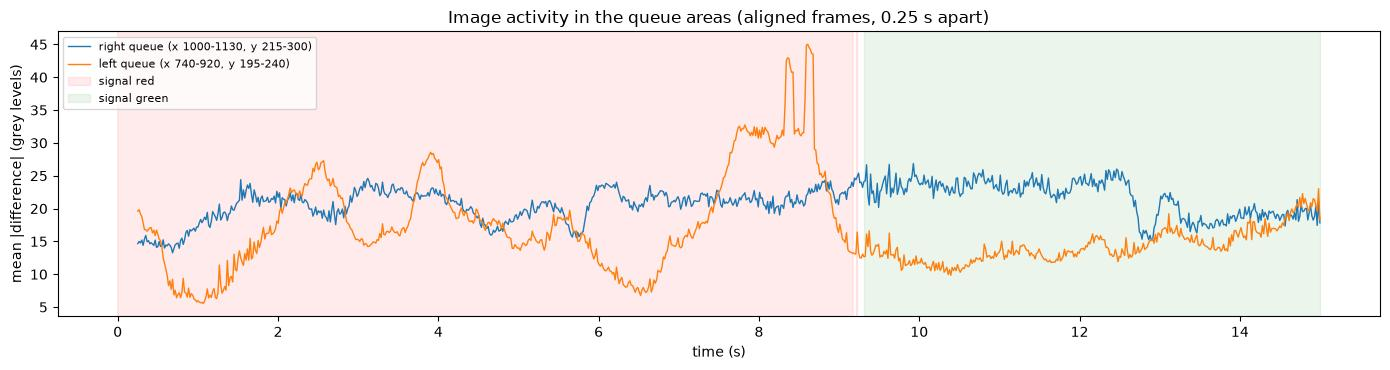

right queue (x 1000-1130, y 215-300)     mean in red 20.42 | mean in green 21.61 | green/red ratio 1.06
left queue (x 740-920, y 195-240)        mean in red 18.28 | mean in green 14.34 | green/red ratio 0.78


In [18]:
fig, ax = plt.subplots(figsize=(14, 3.8))
for name, values in activity.items():
    ax.plot(times_s, values, linewidth=1, label=name)
red_mask = states == "red"
ax.fill_between(times_s, 0, 1, where=red_mask, transform=ax.get_xaxis_transform(), color="red", alpha=0.08, label="signal red")
ax.fill_between(times_s, 0, 1, where=states == "green", transform=ax.get_xaxis_transform(), color="green", alpha=0.08, label="signal green")
ax.set(xlabel="time (s)", ylabel="mean |difference| (grey levels)", title="Image activity in the queue areas (aligned frames, 0.25 s apart)")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "queue_activity.png", dpi=100)
plt.show()

activity_summary = {}
for name, values in activity.items():
    values = np.array(values)
    during_red, during_green = np.nanmean(values[states == "red"]), np.nanmean(values[states == "green"])
    activity_summary[name] = {"mean_red": float(during_red), "mean_green": float(during_green), "ratio": float(during_green / during_red)}
    print(f"{name:<40} mean in red {during_red:5.2f} | mean in green {during_green:5.2f} | green/red ratio {during_green / during_red:.2f}")

To see what is actually happening there, the same area in aligned frames before and after the change. The dashed row and the carriageway limits are drawn in white.

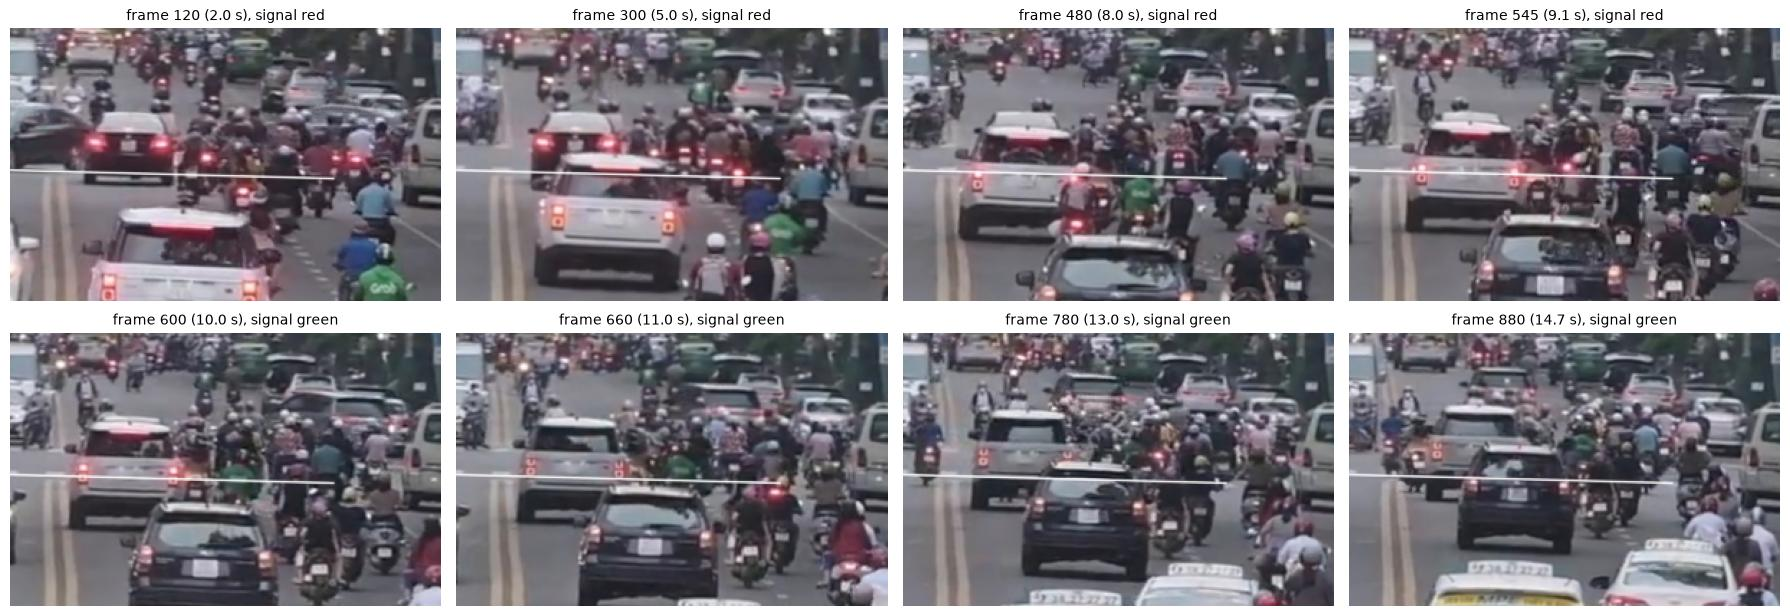

In [19]:
FAR_ROWS, FAR_COLS = (150, 340), (900, 1200)
FAR_FRAMES = [120, 300, 480, 545, 600, 660, 780, 880]
fig, axes = plt.subplots(2, 4, figsize=(18, 6.4))
far_row = next(line for line in SCENE["lines"] if line["id"] == "far_row")
for ax, k in zip(axes.ravel(), FAR_FRAMES):
    aligned = cv2.warpAffine(read_frame_at(SAMPLE_VIDEO, k)["image"], similarity_matrix(similarity_params[k]), (W, H))
    cv2.polylines(aligned, [np.array(far_row["points"], dtype=np.int32)], False, (255, 255, 255), 1, cv2.LINE_AA)
    ax.imshow(cv2.cvtColor(aligned[FAR_ROWS[0]:FAR_ROWS[1], FAR_COLS[0]:FAR_COLS[1]], cv2.COLOR_BGR2RGB))
    ax.set_title(f"frame {k} ({k / FPS:.1f} s), signal {states[k]}", fontsize=10)
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "far_area_over_time.jpg", dpi=90)
plt.show()

**Reading the evidence.**

- Activity on the right carriageway does not rise after the change to green (green/red ratio 1.06).
- The frames show vehicles crawling forward during both phases, with no visible stop-and-release at the far row.
- Activity in the left comparison area does fall after the change (ratio 0.78). But that rests on a single transition, and the red phase includes a large spike at about 8–9 s, so it proves little.

**Conclusion for the configuration.** The signal's *state* is readable, but this clip does not establish *which traffic it governs* or *where its stop line is*. One possible explanation is that its stop line lies farther up the road, beyond what can be resolved, but that is unverified. So `governs_status` is `"unverified"`, and the far row must not be treated as this signal's stop line: a rule such as "crossed the far row while red" would flag ordinary crawling traffic.

## 6. Do the regions and directions match the observed traffic?

### 6.1 Direction agreement

We split each trajectory into short segments of 15 frames (0.25 s) and ignore segments that barely move (under 8 px), since those are mostly box jitter. For each remaining segment inside a carriageway, we compute the angle between its motion and the allowed direction at that position.

In [20]:
SEGMENT_FRAMES, MIN_SEGMENT_MOVE = 15, 8


inside = point_in_polygon


def direction_agreement(scene: dict, region_id: str) -> dict:
    region = region_by_id(scene, region_id)
    vp = np.array(scene["vanishing_point"], dtype=np.float64)
    tolerance = np.cos(np.radians(region["direction_tolerance_deg"]))
    agree = oppose = other = 0
    tracks_seen, tracks_opposing = set(), {}
    for track_id, points in reference_tracks.items():
        for i in range(0, len(points) - SEGMENT_FRAMES, SEGMENT_FRAMES):
            a, b = points[i], points[i + SEGMENT_FRAMES]
            motion = b - a
            if np.linalg.norm(motion) < MIN_SEGMENT_MOVE or not inside(region["polygon"], (a + b) / 2):
                continue
            tracks_seen.add(track_id)
            cosine = float(motion @ allowed_direction_unit(region, (a + b) / 2, vp) / np.linalg.norm(motion))
            if cosine >= tolerance:
                agree += 1
            elif cosine <= -tolerance:
                oppose += 1
                tracks_opposing[track_id] = tracks_opposing.get(track_id, 0) + 1
            else:
                other += 1
    total = agree + oppose + other
    return {"segments": total, "tracks": len(tracks_seen), "agree": agree, "oppose": oppose, "other": other,
            "agree_share": agree / total if total else None, "tracks_opposing": tracks_opposing}


agreement = {region_id: direction_agreement(SCENE, region_id) for region_id in ("right_carriageway", "left_carriageway")}
for region_id, a in agreement.items():
    print(f"{region_id:<20} {a['segments']:>4} moving segments in {a['tracks']:>3} tracks | agree {a['agree']:>4} | oppose {a['oppose']:>3} | other {a['other']:>3} | "
          f"agree share {a['agree_share']:.0%} | tracks with opposing segments: {a['tracks_opposing']}")

right_carriageway     142 moving segments in  20 tracks | agree  127 | oppose   7 | other   8 | agree share 89% | tracks with opposing segments: {'3': 1, '2': 3, '27': 1, '107': 1, '125': 1}
left_carriageway       14 moving segments in   3 tracks | agree   10 | oppose   2 | other   2 | agree share 71% | tracks with opposing segments: {'9': 2}


### 6.2 Where do tracks spend their time?

Inside the always-visible area, every track point should fall in some region. Points outside all regions mean the geometry misses part of the traffic. Points beyond that area are excluded on purpose: the geometry cannot be defined there, and most of them come from boxes clipped at the bottom border, whose bottom-center is not the vehicle's real position.

left_carriageway        1880 track points (  5.8%)
right_carriageway       5512 track points ( 17.1%)
junction               17963 track points ( 55.8%)
parking_left             684 track points (  2.1%)
parking_right           5159 track points ( 16.0%)
far_zone                 840 track points (  2.6%)
outside all regions      142 track points (  0.4%)
Not counted: 2573 points beyond the always-visible area, mostly boxes clipped at the bottom of the image


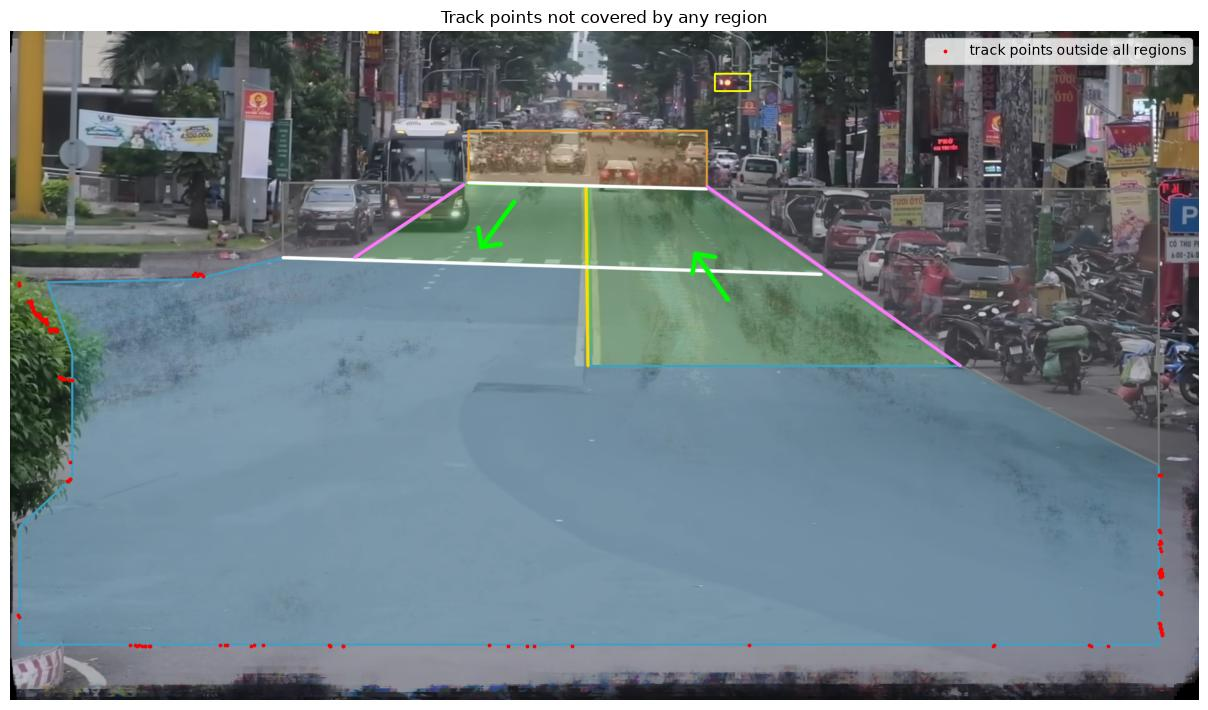

In [21]:
occupancy = {r["id"]: 0 for r in SCENE["regions"]}
outside, beyond_visible = 0, 0
outside_points = []
vx1, vy1, vx2, vy2 = ALWAYS_VISIBLE
for points in reference_tracks.values():
    for point in points:
        if not (vx1 <= point[0] <= vx2 and vy1 <= point[1] <= vy2):
            beyond_visible += 1
            continue
        for region in SCENE["regions"]:
            if inside(region["polygon"], point):
                occupancy[region["id"]] += 1
                break
        else:
            outside += 1
            outside_points.append(point)
total_points = sum(occupancy.values()) + outside
for region_id, n in occupancy.items():
    print(f"{region_id:<20} {n:>7} track points ({n / total_points:6.1%})")
print(f"{'outside all regions':<20} {outside:>7} track points ({outside / total_points:6.1%})")
print(f"Not counted: {beyond_visible} points beyond the always-visible area, mostly boxes clipped at the bottom of the image")
outside_points = np.array(outside_points).reshape(-1, 2)
fig, ax = plt.subplots(figsize=(13, 7.2))
ax.imshow(cv2.cvtColor(draw_scene(stabilized, SCENE), cv2.COLOR_BGR2RGB))
if len(outside_points):
    ax.scatter(outside_points[:, 0], outside_points[:, 1], s=3, c="red", label="track points outside all regions")
    ax.legend()
ax.set_title("Track points not covered by any region")
ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "uncovered_points.jpg", dpi=80)
plt.show()

## 7. Persist, reload, and verify against the video

### 7.1 Saving and loading with validation

`load_scene_config`, now in `src/traffic_violation_detection/scene.py`, is the only way later notebooks should read the file. It rejects configurations that do not fit the video, so a wrong or stale file fails loudly instead of producing wrong violations silently.

In [22]:
import inspect

print(inspect.getsource(load_scene_config))
SCENE_PATH.write_text(json.dumps(SCENE, indent=2) + "\n")
scene = load_scene_config(SCENE_PATH, W, H)
print("Saved and reloaded", SCENE_PATH.relative_to(PROJECT_ROOT), "| identical to the definition:", scene == json.loads(json.dumps(SCENE)))

def load_scene_config(path: str | Path, width: int, height: int) -> dict:
    """Load a scene configuration and check it against the video's size.

    Raises ValueError for a configuration that does not fit, so a wrong or stale
    file fails loudly instead of producing wrong violations silently.
    """
    scene = json.loads(Path(path).read_text())
    if scene.get("schema_version") != 1:
        raise ValueError(f"Unsupported schema_version: {scene.get('schema_version')}")
    if (scene["video"]["width"], scene["video"]["height"]) != (width, height):
        raise ValueError(f"Scene is for {scene['video']['width']}x{scene['video']['height']}, video is {width}x{height}")
    x1, y1, x2, y2 = scene["coordinates"]["always_visible_xyxy"]

    def check_points(owner: str, points) -> None:
        for x, y in points:
            if not (x1 <= x <= x2 and y1 <= y <= y2):
                raise ValueError(f"{owner}: point ({x}, {y}) is outside the always-visible area")

    region_ids = set

The validator should reject broken configurations:

In [23]:
def rejected(mutate, width=W, height=H) -> str | None:
    broken = copy.deepcopy(SCENE)
    mutate(broken)
    path = OUTPUT_DIR / "broken_scene_test.json"
    path.write_text(json.dumps(broken))
    try:
        load_scene_config(path, width, height)
        return None
    except ValueError as error:
        return str(error)
    finally:
        path.unlink()


rejection_tests = {
    "wrong video size": lambda: rejected(lambda s: None, width=1280, height=720),
    "unsupported schema": lambda: rejected(lambda s: s.update(schema_version=99)),
    "polygon with 2 points": lambda: rejected(lambda s: s["regions"][0].update(polygon=[[800, 300], [900, 300]])),
    "degenerate polygon": lambda: rejected(lambda s: s["regions"][0].update(polygon=[[800, 300], [850, 300], [900, 300]])),
    "point outside visible area": lambda: rejected(lambda s: s["lines"][0].update(points=[[930, 250], [933, 1070]])),
    "unknown direction": lambda: rejected(lambda s: s["regions"][0].update(allowed_direction="sideways")),
    "signal governs unknown region": lambda: rejected(lambda s: s["signals"][0].update(governs_regions=["nowhere"])),
}
rejection_results = {name: test() for name, test in rejection_tests.items()}
for name, message in rejection_results.items():
    print(f"{name:<32} -> {message or 'NOT REJECTED'}")

wrong video size                 -> Scene is for 1920x1080, video is 1280x720
unsupported schema               -> Unsupported schema_version: 99
polygon with 2 points            -> left_carriageway: a polygon needs at least 3 points
degenerate polygon               -> left_carriageway: polygon has no area
point outside visible area       -> center_line: point (933, 1070) is outside the always-visible area
unknown direction                -> left_carriageway: unknown direction sideways
signal governs unknown region    -> signal_main: governs unknown regions ['nowhere']


### 7.2 Does the geometry stay on the road in the raw video?

This is the check that matters. We project the configuration from reference coordinates back into the **raw, unaligned** pixels of frames far apart in time. The camera moves by tens of pixels between these frames, and the lines should follow the road markings anyway.

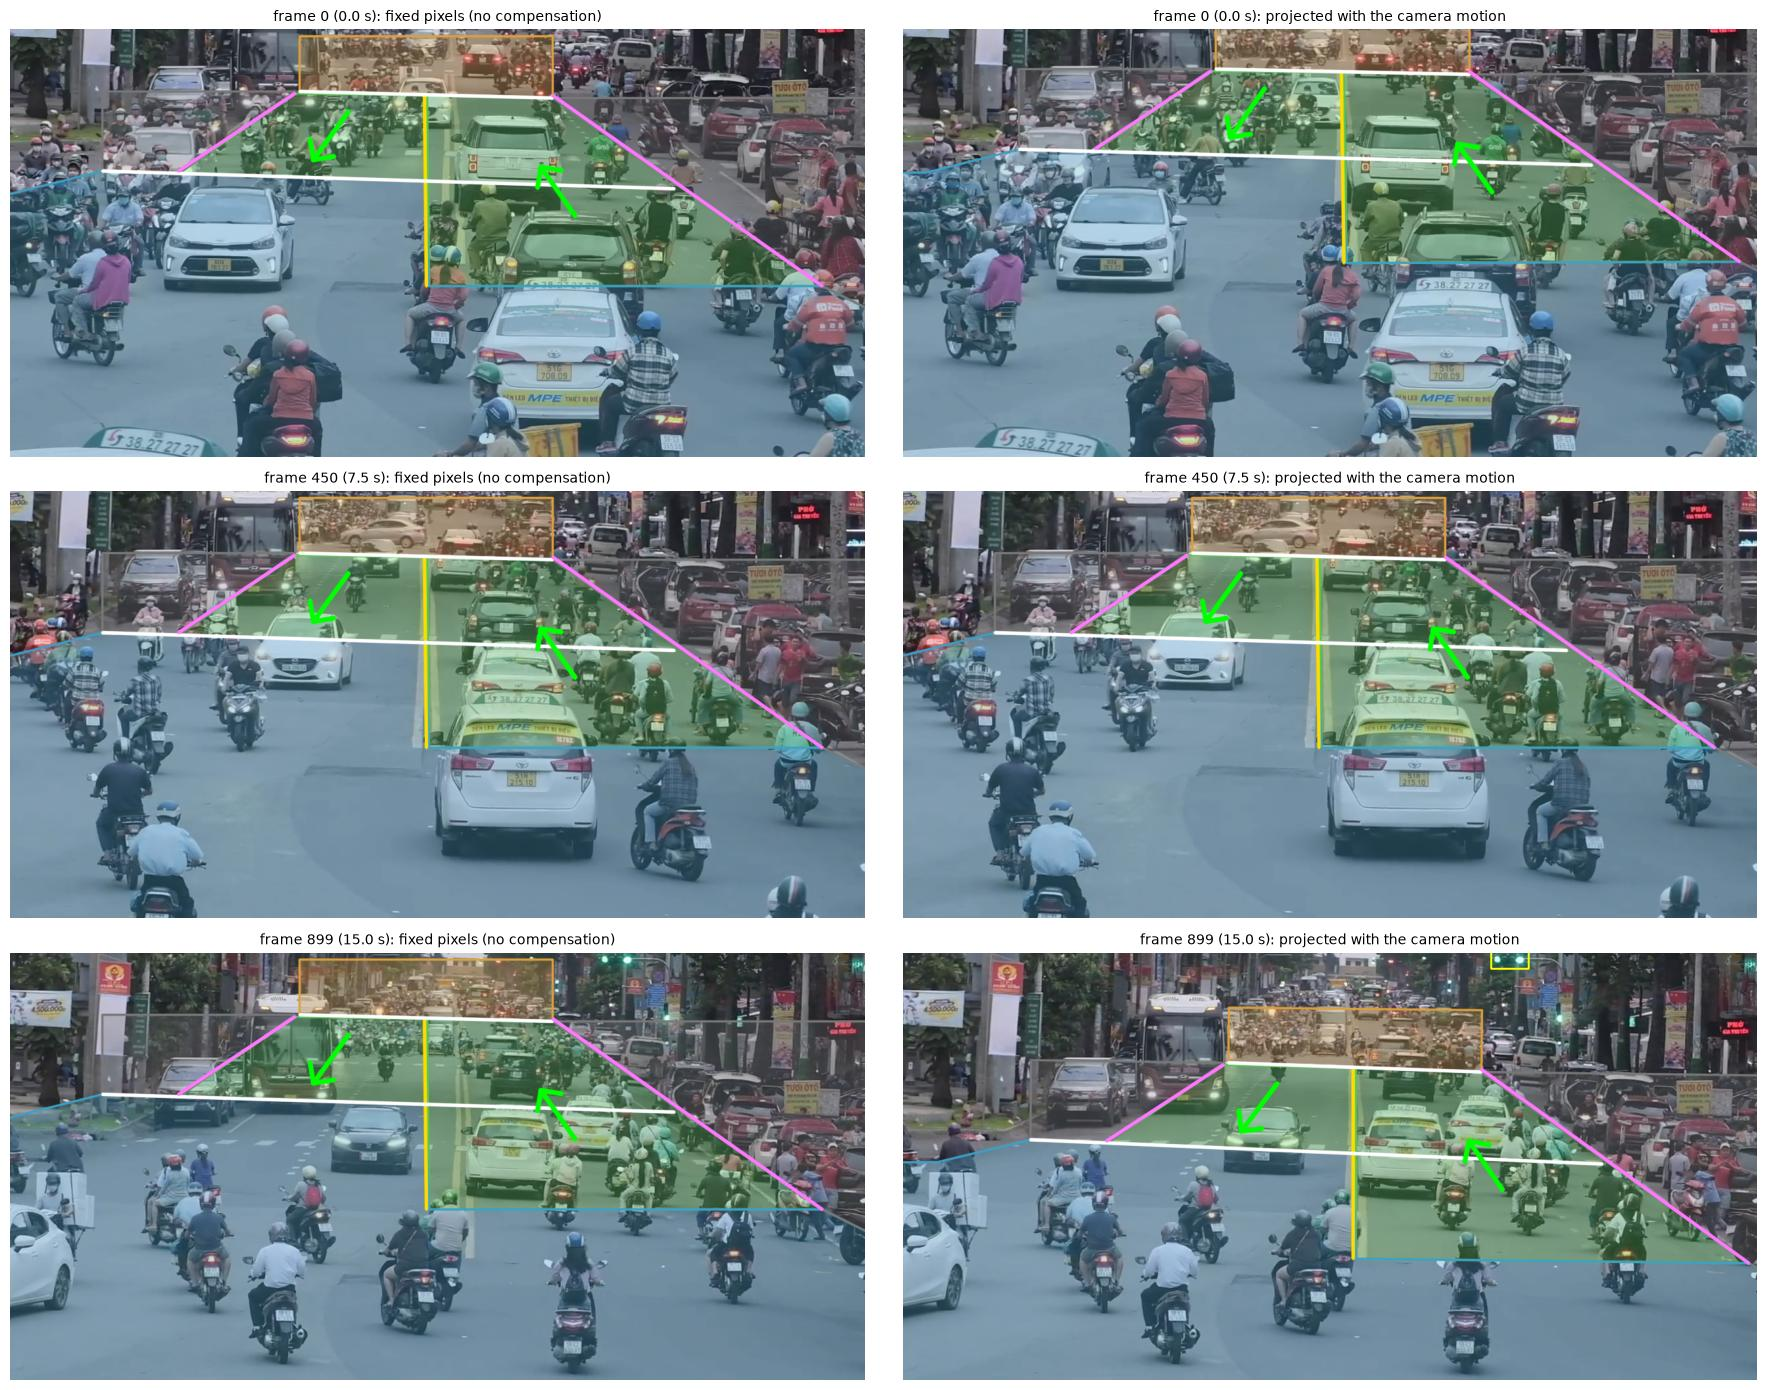

In [24]:
CHECK_FRAMES = [0, 450, 899]
fig, axes = plt.subplots(len(CHECK_FRAMES), 2, figsize=(18, 14))
for row, k in enumerate(CHECK_FRAMES):
    image = read_frame_at(SAMPLE_VIDEO, k)["image"]
    fixed = draw_scene(image, scene)                                               # as if the camera were static
    followed = draw_scene(image, scene, mapper=lambda p, k=k: from_reference(k, p))  # with the frame's transform
    for col, (canvas, label) in enumerate([(fixed, "fixed pixels (no compensation)"), (followed, "projected with the camera motion")]):
        axes[row, col].imshow(cv2.cvtColor(canvas[150:800, 300:1600], cv2.COLOR_BGR2RGB))
        axes[row, col].set_title(f"frame {k} ({k / FPS:.1f} s): {label}", fontsize=10)
        axes[row, col].axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "scene_on_raw_frames.jpg", dpi=75)
plt.show()

**A quantitative check on the signal.** The traffic-light boxes from Notebook 02 are independent of this notebook's keypoints. During the red phase, the main head does not change, so its box centers should form a tight cluster. We compare their spread in raw pixels and in reference coordinates.

In [25]:
raw_centers, reference_centers = [], []
for k, record in enumerate(detection_records):
    if states[k] != "red":
        continue
    for d in record["detections"]:
        x1_b, y1_b, x2_b, y2_b = d["bbox_xyxy"]
        center = [(x1_b + x2_b) / 2, (y1_b + y2_b) / 2]
        if d["class_name"] != "traffic light" or d["confidence"] < 0.25:
            continue
        mapped = to_reference(k, [center])[0]
        rx1, ry1, rx2, ry2 = signal_config["roi_xyxy"]
        if rx1 - 20 <= mapped[0] <= rx2 + 20 and ry1 - 20 <= mapped[1] <= ry2 + 20:
            raw_centers.append(center)
            reference_centers.append(mapped)
raw_centers, reference_centers = np.array(raw_centers), np.array(reference_centers)
raw_spread, reference_spread = raw_centers.std(axis=0), reference_centers.std(axis=0)
print(f"{len(raw_centers)} confident traffic-light boxes on the main head during red")
print(f"Spread of box centers (std, px): raw x {raw_spread[0]:.1f}, y {raw_spread[1]:.1f} | reference x {reference_spread[0]:.1f}, y {reference_spread[1]:.1f}")

419 confident traffic-light boxes on the main head during red
Spread of box centers (std, px): raw x 8.0, y 15.3 | reference x 2.0, y 1.0


### 7.3 Save the derived data for Notebook 05

In [26]:
camera_motion_path = OUTPUT_DIR / "video-test.camera_motion.json"
camera_motion_path.write_text(json.dumps({
    "video": "data/video-test.mp4",
    "reference_frame_index": REFERENCE_FRAME,
    "model": "similarity: x' = a*x - b*y + tx, y' = b*x + a*y + ty, from frame pixels to reference pixels",
    "always_visible_xyxy": ALWAYS_VISIBLE,
    "frames": [{"frame_index": k, "a": float(p[0]), "b": float(p[1]), "tx": float(p[2]), "ty": float(p[3]), "inliers": int(inlier_counts[k])}
               for k, p in enumerate(similarity_params)],
}))

trajectories_ref_path = OUTPUT_DIR / "video-test.ocsort-byte.trajectories_ref.json"
trajectories_ref_path.write_text(json.dumps({
    "tracking_session": trajectory_file["tracking_session"],
    "scene_id": SCENE["scene_id"],
    "position": "bottom-center of the track box, in reference-frame pixels",
    "tracks": {track_id: {"class_name": tracks[track_id]["class_name"], "frames": tracks[track_id]["frames"],
                          "timestamps_s": tracks[track_id]["timestamps_s"],
                          "points_ref": np.round(points, 2).tolist()}
               for track_id, points in reference_tracks.items()},
}))

signal_path = OUTPUT_DIR / "video-test.signal_main.json"
signal_path.write_text(json.dumps({
    "signal_id": signal_config["id"], "method": "bright red/green pixel counts in the ROI of aligned frames",
    "min_lamp_pixels": MIN_LAMP_PIXELS, "dominance": DOMINANCE, "frames": signal_records,
}))

summary = {
    "registration": {"model": "similarity", "median_inliers": float(np.median(inlier_counts)), "min_inliers": int(inlier_counts.min()),
                     "residuals_median_px": {n: float(np.median(r["similarity"])) for n, r in residuals.items()},
                     "residuals_max_px": {n: float(np.max(r["similarity"])) for n, r in residuals.items()},
                     "sharpness_raw": sharpness_raw, "sharpness_stabilized": sharpness_stabilized},
    "always_visible_xyxy": ALWAYS_VISIBLE,
    "signal": {"frames_per_state": counts, "last_red_frame": last_red, "first_green_frame": first_green},
    "crossings_by_test_line": crossing_table,
    "queue_activity": activity_summary,
    "direction_agreement": agreement,
    "track_point_occupancy": {**occupancy, "outside": outside, "beyond_always_visible": beyond_visible},
}
(OUTPUT_DIR / "scene_summary.json").write_text(json.dumps(summary, indent=2, default=int))
for path in (SCENE_PATH, camera_motion_path, trajectories_ref_path, signal_path):
    print("wrote", path.relative_to(PROJECT_ROOT), f"({path.stat().st_size / 1e3:.0f} KB)")

wrote configs/scenes/video-test.json (6 KB)
wrote outputs/04_traffic_scene_configuration/video-test.camera_motion.json (129 KB)
wrote outputs/04_traffic_scene_configuration/video-test.ocsort-byte.trajectories_ref.json (1426 KB)
wrote outputs/04_traffic_scene_configuration/video-test.signal_main.json (98 KB)


## 8. Validation

In [27]:
STABLE_POINTS = ["banner", "shop_sign", "yellow_pole", "p_sign", "barrier_bottom_left"]  # textured, rarely occluded
stable_values = [v for n in STABLE_POINTS for v in residuals[n]["similarity"]]
# Rasterized polygons include their boundary pixels, so neighbours sharing an edge "overlap" along it.
# Eroding each mask by 1 px leaves only real overlap.
masks = {r["id"]: cv2.erode(cv2.fillPoly(np.zeros((H, W), np.uint8), [np.array(r["polygon"], dtype=np.int32)], 1), np.ones((3, 3), np.uint8)) for r in scene["regions"]}
ids = list(masks)
overlap_px = max(int((masks[a] & masks[b]).sum()) for i, a in enumerate(ids) for b in ids[i + 1:])
reloaded_motion = json.loads(camera_motion_path.read_text())
round_trip = from_reference(899, to_reference(899, [[100.0, 200.0], [1500.0, 900.0]]))

checks = {
    "transform of the reference frame is the identity (< 0.5 px)": np.abs(to_reference(REFERENCE_FRAME, [[0.0, 0.0], [W, H]]) - np.array([[0, 0], [W, H]])).max() < 0.5,
    "every frame has at least 500 inliers": int(inlier_counts.min()) >= 500,
    "residual on stable static points: median <= 1 px": float(np.median(stable_values)) <= 1,
    "residual on stable static points: max <= 5 px": float(np.max(stable_values)) <= 5,
    "aligned background sharper than the unaligned one": sharpness_stabilized > sharpness_raw,
    "reference <-> frame mapping round-trips (< 0.01 px)": np.abs(round_trip - np.array([[100.0, 200.0], [1500.0, 900.0]])).max() < 0.01,
    "scene file reloads identical to its definition": scene == json.loads(json.dumps(SCENE)),
    "regions do not overlap (under 100 px after removing shared edges)": overlap_px < 100,
    "all broken configurations are rejected": all(rejection_results.values()),
    "camera motion file has one record per frame": [f["frame_index"] for f in reloaded_motion["frames"]] == list(range(N_FRAMES)),
    "signal has one state per frame": len(signal_records) == N_FRAMES,
    "signal change matches the crops of Notebook 00 (red -> green between 7.5 and 11.2 s)": 7.5 <= first_green / FPS <= 11.2,
    "signal stays one color on each side of the change": set(states[:last_red - 10]) == {"red"} and set(states[first_green + 10:]) == {"green"},
    "signal box spread tightens after alignment": reference_spread.max() < raw_spread.max(),
    "at least 95% of track points in the always-visible area fall in a region": outside / total_points <= 0.05,
    "right carriageway: at least 80% of moving segments agree": agreement["right_carriageway"]["agree_share"] >= 0.8,
}
for name, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")
print(f"(largest overlap between regions: {overlap_px} px; region-overlap and coverage thresholds are sanity limits, not accuracy claims)")
assert all(checks.values()), "One or more checks failed - see above"

[PASS] transform of the reference frame is the identity (< 0.5 px)
[PASS] every frame has at least 500 inliers
[PASS] residual on stable static points: median <= 1 px
[PASS] residual on stable static points: max <= 5 px
[PASS] aligned background sharper than the unaligned one
[PASS] reference <-> frame mapping round-trips (< 0.01 px)
[PASS] scene file reloads identical to its definition
[PASS] regions do not overlap (under 100 px after removing shared edges)
[PASS] all broken configurations are rejected
[PASS] camera motion file has one record per frame
[PASS] signal has one state per frame
[PASS] signal change matches the crops of Notebook 00 (red -> green between 7.5 and 11.2 s)
[PASS] signal stays one color on each side of the change
[PASS] signal box spread tightens after alignment
[PASS] at least 95% of track points in the always-visible area fall in a region
[PASS] right carriageway: at least 80% of moving segments agree
(largest overlap between regions: 0 px; region-overlap and 

## Results

All numbers come from the outputs above.

**Camera registration works, and it changes how the scene can be read.**

- Masking detected objects raises the RANSAC inlier ratio to a median of 84%, from 10–16% in Notebook 00.
- Static points that move by a median of about 25–33 px in the raw video stay within 0–1 px (median) and at most about 3 px after alignment.
- Box centers of the main signal head, an independent check, tighten from a spread of 8.0 / 15.3 px (x / y) to 2.0 / 1.0 px.
- **A similarity transform was chosen over a homography.** Only about 1% of the matches lie in the lower half of the image, so the homography extrapolates over the road surface: its largest residuals there are 17 px and 92 px, against 2.2 px for the similarity.

**The scene is better understood than in Notebook 00.**

- The stabilized background reveals a double yellow center line, two transverse dashed rows, solid edge lines, and a wide marking-free junction in the lower half.
- The dominant traffic flow crosses the junction diagonally from the lower right toward the left (85 of 136 tracks are mostly leftward). Part of it bends up onto the right carriageway.
- This refines Notebook 00, which described most near-field traffic as simply travelling away from the camera.

**The configuration fits the video.**

- Projected back into raw frames using the camera motion, the geometry stays on the road markings at the start, middle and end of the clip.
- The center line and the two edge lines meet within about 1.5 px of one vanishing point.
- Inside the always-visible area, 99.6% of track points fall in a region.
- On the right carriageway, 89% of moving segments (127 of 142, in 20 tracks) agree with the allowed direction.

**The signal state is readable; what it governs is not established.**

- The state reads red for 553 frames and green for 342, with 5 `unknown` frames during the change at about 9.2–9.3 s.
- Tracked crossings of the far row are too few to conclude anything (1–2 vehicles).
- Motion measured without the detector does not rise on the right carriageway after the change (green/red ratio 1.06), and vehicles keep crawling forward in both phases.
- **The far row must not be used as this signal's stop line.**

## Readiness of each violation type for Notebook 05

This updates Notebook 00's table. Notebook 02 concluded that signal localization made a red-light rule more feasible; after this notebook, that is no longer the case for this clip.

| Violation type | What is available | What is missing | Assessment |
| --- | --- | --- | --- |
| Wrong-way driving | Carriageway regions, allowed directions, supporting data on the right carriageway | Whether any real case occurs. The 9 opposing segments in 6 tracks are not yet inspected and may be box jitter | **Most feasible** |
| Center-line crossing | Center line for y ≈ 250–540 | Not yet evaluated; turning traffic near the junction may need separate handling | Possible second candidate |
| Red-light running | Readable signal state | The stop line and the traffic governed by this signal; tracking also fails near the far row | **Not supported by this clip** |

## Limitations

- **Hand-drawn, single-clip geometry.** Coordinates were read from the stabilized background and are valid only for this clip and camera position. The far row is extrapolated across the right carriageway, where traffic hides it.
- **No camera calibration.** Geometry is in pixels, so nothing here gives metric distances or speeds.
- **Unknown legal meaning.** The dashed rows may or may not be stop or give-way lines. Local traffic rules for this junction were not checked.
- **Sparse evidence.**
  - The left carriageway has only 14 moving segments in 3 tracks (71% agreement), which is too little to support its direction. That direction rests on the orientation of the bus and of waiting vehicles.
  - The signal reading is based on one clip with one change, and no yellow phase was observed. Its thresholds may not hold in other lighting.
- **Offline registration.** Every frame is matched to one reference frame in the middle of the clip. A live stream would have to choose a reference frame in advance.
- **Residual precision.** Template matching measures whole pixels, and the 0.42 px median frame-to-frame change in the transform is a mix of real camera motion and estimation noise. Smoothing the transform did not reduce residuals in an exploratory test, so none is applied.
- **Unreliable positions.** Boxes clipped at the image border do not give a real bottom-center. The 2,573 track points beyond the always-visible area are left out of all regions, and box jitter from Notebook 03 remains.

## Conclusion

**Completion criterion** — *the scene configuration can be loaded and used by subsequent violation detection experiments*: **met.**

- `configs/scenes/video-test.json` loads through a validator that rejects broken or mismatched files.
- Its assumptions are written into the file, including the unverified status of the signal.
- Trajectories, camera motion, and signal states are saved in matching coordinates.

**Readiness for integration.** The scene loader, camera-motion mappings and region helpers now live in `src/traffic_violation_detection/scene.py`, with tests in `tests/test_scene.py`. `read_signal_state` stays in this notebook until a rule uses it.

**Next: Notebook 05 — violation detection.** Start with wrong-way driving on the two carriageways, and inspect the opposing segments found here to separate real wrong-way movement from box jitter.